# Surface Water Flow Trends — Internal Basins of Catalonia (2000-2026)

**Objective.** Describe how river flows have evolved in the internal basins of Catalonia using the open data of the Catalan Water Agency (ACA), and test how robust the observed trends are to the choice of stations, the statistical method and the analysis window.

The notebook (1) downloads daily flow records, wastewater treatment plant (WWTP) locations and reservoir volumes; (2) estimates a trend for each gauging station with the Mann-Kendall test and Sen's slope; (3) checks how sensitive the result is to filters and to the end of the series; (4) looks at the 2021-2024 drought and storm Gloria (January 2020); and (5) explores two possible explanations: wastewater effluent and reservoir regulation.

In [1]:
# ── LIBRARIES ──────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyproj
import os

output_dir = 'output'
os.makedirs(output_dir, exist_ok=True)

print('✓ Libraries loaded and output directory ready')

✓ Libraries loaded and output directory ready


## 1. Data download

Three open datasets from the ACA portal (*Dades obertes de Catalunya*) are downloaded directly from their API: river flow and level at gauging stations, wastewater treatment systems (EDAR) and daily volumes of the internal-basin reservoirs. Because the ACA updates them daily, numbers can change slightly between runs.

In [2]:
# ── Download: River flow Data (ACA Public API) ──────────────────────────────────────────────────────────────────
URL_CABALS = ('https://analisi.transparenciacatalunya.cat'
              '/api/views/hprm-xuw7/rows.csv?accessType=DOWNLOAD')

print('Downloading river flow/level data from ACA...')
try: 
    df_cabals_raw = pd.read_csv(URL_CABALS)
    print(f'✓ Data downloaded successfully ({len(df_cabals_raw):,} rows)')
    print('Download date:', pd.Timestamp.today().date())
except Exception as e:
    print(f'Download error: {e}')
    print('Check your internet connection and try again.')

✓ Data downloaded successfully (1,128,168 rows)
Download date: 2026-11-08


In [3]:
# ── Download: WWTP / EDAR System Data (ACA PUBLIC API) ─────────────────────────
URL_EDAR = (
    'https://analisi.transparenciacatalunya.cat'
    '/api/views/k288-dig3/rows.csv?accessType=DOWNLOAD')

print('Downloading WWTP (wastewater treatment plant) data from ACA...')
try:
    df_edar_raw = pd.read_csv(URL_EDAR)
    print(f'✓ Data downloaded successfully ({len(df_edar_raw):,} rows)')
except Exception as e:
    print(f'Download error: {e}')
    print('Check your internet connection and try again.')

✓ Data downloaded successfully (1,715 rows)


In [4]:
# ── DOWNLOAD: RESERVOIR VOLUMES (ACA PUBLIC API) ────────────────────────────────
URL_RES = ('https://analisi.transparenciacatalunya.cat'
           '/api/views/gn9e-3qhr/rows.csv?accessType=DOWNLOAD')

print('Downloading reservoir data from ACA...')
try:
    df_res_raw = pd.read_csv(URL_RES)
    print(f'✓ Data downloaded successfully ({len(df_res_raw):,} rows)')
    print(df_res_raw.columns.tolist())
except Exception as e:
    print(f'Download error: {e}')

✓ Data downloaded successfully (88,263 rows)
['Dia', 'Estació', 'Nivell absolut (msnm)', 'Percentatge volum embassat (%)', 'Volum embassat (hm3)']


## 2. Cleaning and standardization

Column names are standardized and **dates are parsed explicitly as day/month/year**: reading them as month/day silently drops about 60% of the records and swaps day and month in the rest. Only discharge records (m³/s) are kept, with a physical range filter. For the WWTP data only the most recent reporting year is used and coordinates are converted to UTM 31N, the system used by the gauging stations.

In [5]:
# ── Cleaning and Standardization: Flow Data ─────────────────────────────────────
df_cabals = df_cabals_raw.copy()
df_cabals.columns = df_cabals.columns.str.strip().str.lower().str.replace(' ', '_')

col_map = {}
for col in df_cabals.columns:
    if 'dia' in col: col_map['date'] = col
    elif 'codi_estació' in col: col_map['station_code'] = col
    elif col == 'estació': col_map['station'] = col
    elif 'conca' in col and 'sub' not in col: col_map['basin'] = col
    elif 'subconca' in col: col_map['subbasin'] = col
    elif 'utm_x' in col: col_map['x'] = col
    elif 'utm_y' in col: col_map['y'] = col
    elif 'tipus_variable' in col: col_map['variable_type'] = col
    elif col == 'valor': col_map['value'] = col

df_cabals = df_cabals.rename(columns={v: k for k, v in col_map.items()})

n_rows = len(df_cabals)
df_cabals['date'] = pd.to_datetime(df_cabals['date'], format='%d/%m/%Y', errors='coerce')
print(f'Dates that could not be parsed: {df_cabals["date"].isna().sum():,} of {n_rows:,}')
df_cabals['value'] = pd.to_numeric(df_cabals['value'], errors='coerce')
df_cabals['x'] = pd.to_numeric(df_cabals['x'], errors='coerce')
df_cabals['y'] = pd.to_numeric(df_cabals['y'], errors='coerce')

df_flow = df_cabals[df_cabals['variable_type'] == 'Cabal riu'].copy()
df_flow = df_flow.dropna(subset=['date', 'value', 'x', 'y'])
df_flow = df_flow[(df_flow['value'] >= 0) & (df_flow['value'] <= 2000)]

print(f'✓ Clean flow dataset: {len(df_flow):,} valid records ({df_flow["station_code"].nunique()} stations)')
print(f'  Period: {df_flow["date"].min().date()} → {df_flow["date"].max().date()}')
assert df_flow['date'].max() <= pd.Timestamp.today(), 'There are dates in the future'

Dates that could not be parsed: 0 of 1,128,168
✓ Clean flow dataset: 571,534 valid records (88 stations)
  Period: 2000-01-01 → 2026-11-06


In [6]:
# ── Cleaning and Standardization: WWTP (EDAR) Data ──────────────────────────────
df_edar = df_edar_raw.copy()
df_edar.columns = df_edar.columns.str.strip().str.lower().str.replace(' ', '_')

# Keep only the most recent reporting year (avoids duplicated systems across years)
df_edar = df_edar[df_edar['any'] == df_edar['any'].max()].copy()

cols_needed = ['any', 'sistema', 'conca', 'medi_receptor', 'municipi', 'latitud', 'longitud', 'habitants_equivalents', 'cabal_disseny']
df_edar = df_edar[cols_needed].copy()

df_edar = df_edar.rename(columns={
    'sistema': 'wwtp_name',
    'conca': 'basin',
    'medi_receptor': 'receiving_water',
    'municipi': 'municipality',
    'latitud': 'lat',
    'longitud': 'lon',
    'habitants_equivalents': 'population_equivalent',
    'cabal_disseny': 'design_flow_m3_day'  
})

df_edar['design_flow_m3_day'] = pd.to_numeric(df_edar['design_flow_m3_day'], errors='coerce').fillna(0)
df_edar['lat'] = pd.to_numeric(df_edar['lat'], errors='coerce')
df_edar['lon'] = pd.to_numeric(df_edar['lon'], errors='coerce')
df_edar['population_equivalent'] = pd.to_numeric(df_edar['population_equivalent'], errors='coerce').fillna(0)
df_edar = df_edar.dropna(subset=['lat', 'lon'])

print(f'✓ Clean WWTP dataset: {len(df_edar):,} treatment systems (year {df_edar["any"].max() if "any" in df_edar.columns else "N/A"})')

✓ Clean WWTP dataset: 578 treatment systems (year 2026)


In [7]:
# ── Convert WWTP Coordinates to UTM (to match river station coordinates) ───────
import pyproj

transformer = pyproj.Transformer.from_crs('EPSG:4326', 'EPSG:25831', always_xy=True)
df_edar['x'], df_edar['y'] = transformer.transform(df_edar['lon'].values, df_edar['lat'].values)

print(f'✓ WWTP coordinates converted to UTM 31N')
print(df_edar[['wwtp_name', 'lat', 'lon', 'x', 'y']].head(3))

✓ WWTP coordinates converted to UTM 31N
                wwtp_name        lat       lon              x             y
1110               ABRERA  41.507060  1.917910  409694.891785  4.595613e+06
1111     ALFARRÀS-ALMENAR  41.787056  0.595019  300155.834598  4.628929e+06
1112  BRISES DEL MAR, LES  41.166482  1.391112  365028.725572  4.558486e+06


In [8]:
# ── CLEANING: RESERVOIR DATA ────────────────────────────────────────────────────
df_res = df_res_raw.copy()
df_res.columns = df_res.columns.str.strip().str.lower().str.replace(' ', '_')

rename = {}
for col in df_res.columns:
    if col == 'dia':                    rename[col] = 'date'
    elif col.startswith('estaci'):      rename[col] = 'reservoir'
    elif col.startswith('percentatge'): rename[col] = 'pct_full'
    elif col.startswith('volum'):       rename[col] = 'volume_hm3'
    elif col.startswith('nivell'):      rename[col] = 'level_masl'
df_res = df_res.rename(columns=rename)

print('First raw dates:', df_res['date'].head(3).tolist())
sample = str(df_res['date'].iloc[0])
fmt = '%d/%m/%Y' if '/' in sample else None           # day-first only if the source uses slashes
df_res['date'] = pd.to_datetime(df_res['date'], format=fmt, errors='coerce')
n_bad = df_res['date'].isna().sum()
print(f'Dates that could not be parsed: {n_bad} of {len(df_res):,}')
assert n_bad == 0, 'Date parsing failed: check the raw format'

for c in ['pct_full', 'volume_hm3', 'level_masl']:
    df_res[c] = pd.to_numeric(df_res[c], errors='coerce')

print(df_res.groupby('reservoir')['date'].agg(['min', 'max', 'count']).to_string())

First raw dates: ['22/10/2026', '22/10/2026', '23/10/2026']
Dates that could not be parsed: 0 of 88,263
                                                       min        max  count
reservoir                                                                   
Embassament de Darnius Boadella (Darnius)       2000-01-01 2026-11-06   9807
Embassament de Foix (Castellet i la Gornal)     2000-01-01 2026-11-06   9807
Embassament de Riudecanyes                      2000-01-01 2026-11-06   9807
Embassament de Sant Ponç (Clariana de Cardener) 2000-01-01 2026-11-06   9807
Embassament de Sau (Vilanova de Sau)            2000-01-01 2026-11-06   9807
Embassament de Siurana (Cornudella de Montsant) 2000-01-01 2026-11-06   9807
Embassament de Susqueda (Osor)                  2000-01-01 2026-11-06   9807
Embassament de la Baells (Cercs)                2000-01-01 2026-11-06   9807
Embassament de la Llosa del Cavall (Navès)      2000-01-01 2026-11-06   9807


In [9]:
!pip install pymannkendall statsmodels --quiet


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Trend analysis per station
For each station we compute a monthly mean flow series and test for a monotonic trend using the **Mann-Kendall test**, estimating its magnitude with **Sen's slope** (both are robust to outliers and do not assume normally distributed data).

To keep only reliable stations, we require:
- At least **24 months** of data,
- A real time span of at least **15 years**,
- At least **60% of months** with valid data inside that span.

The trend is expressed as a **percentage of the station's mean flow per year**, so rivers of different sizes can be compared.

In [10]:
# ── TREND PER STATION: MANN-KENDALL + SEN'S SLOPE ───────────────────────────────
import pymannkendall as mk
from scipy.stats import theilslopes

def compute_trend(group, min_span=15, min_cov=60, max_gap=None, hamed_rao=False):
    monthly = group.set_index('date')['value'].resample('ME').mean().dropna()
    if len(monthly) < 24:
        return None

    span_years = (monthly.index[-1] - monthly.index[0]).days / 365.25
    if span_years < min_span:
        return None

    total_months = (monthly.index[-1].to_period('M') - monthly.index[0].to_period('M')).n + 1
    coverage_pct = len(monthly) / total_months * 100
    if coverage_pct < min_cov:
        return None

    longest_gap = (monthly.index.to_series().diff().dt.days.dropna() / 30.44).max()
    if max_gap is not None and longest_gap > max_gap:
        return None

    mk_result = (mk.hamed_rao_modification_test(monthly.values) if hamed_rao
                 else mk.original_test(monthly.values))
    years_elapsed = (monthly.index - monthly.index[0]).days / 365.25
    slope, intercept, low_ci, high_ci = theilslopes(monthly.values, years_elapsed)
    mean_flow = monthly.mean()

    return pd.Series({
        'trend_direction': mk_result.trend,
        'sen_slope_per_year': slope,
        'sen_slope_pct_per_year': slope / mean_flow * 100,
        'mean_flow': mean_flow,
        'p_value': mk_result.p,
        'significant': mk_result.h,
        'n_months': len(monthly),
        'span_years': round(span_years, 1),
        'coverage_pct': round(coverage_pct, 1),
        'longest_gap_months': round(longest_gap, 1)
    })

def build_trends(df, **settings):
    info = (df.groupby('station_code')
              .agg(station=('station', 'first'), basin=('basin', 'first'),
                   x=('x', 'first'), y=('y', 'first'))
              .reset_index())
    res = (df.groupby('station_code')
             .apply(compute_trend, include_groups=False, **settings)
             .dropna().reset_index())
    return info.merge(res, on='station_code', how='inner')

stations_trends = build_trends(df_flow, max_gap=36, hamed_rao=True)
print(f'✓ Trend computed for {len(stations_trends)} stations')

c:\Users\cadam\AppData\Local\Programs\Python\Python313\Lib\site-packages\pymannkendall\pymannkendall.py:103: RuntimeWarning: invalid value encountered in sqrt
  z = (s + 1)/np.sqrt(var_s)


✓ Trend computed for 48 stations


## 4. Overview: trends across the network

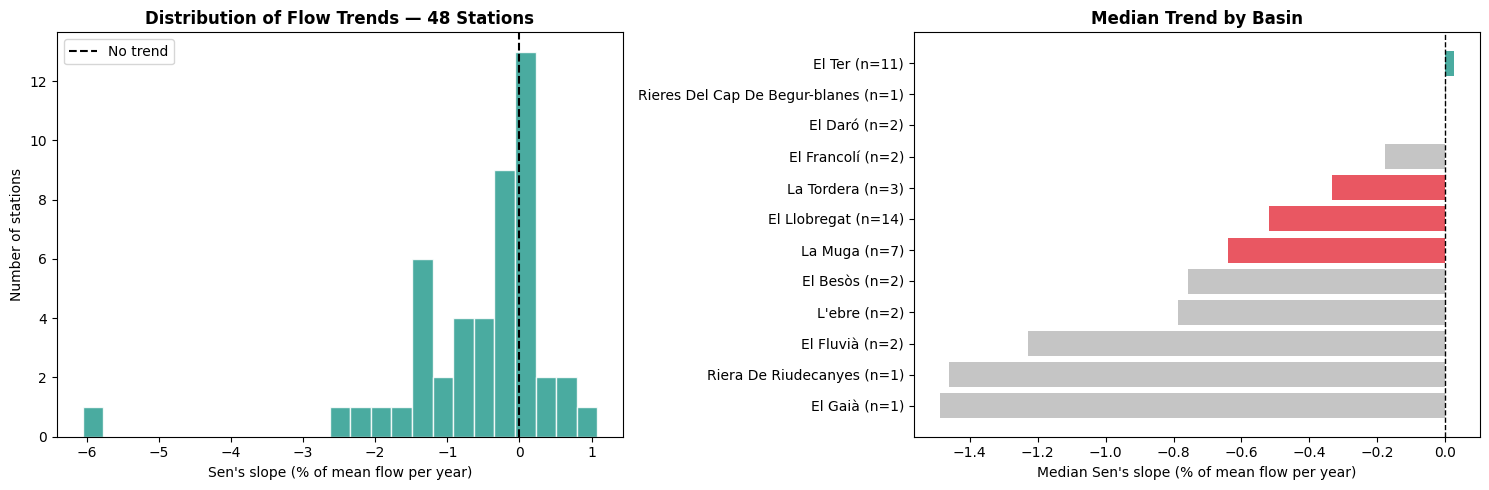

✓ Figure saved: output/01_trend_distribution.png

                                count      mean    median
basin                                                    
El Gaià                             1 -1.488840 -1.488840
Riera De Riudecanyes                1 -1.461170 -1.461170
El Fluvià                           2 -1.229427 -1.229427
L'ebre                              2 -0.786896 -0.786896
El Besòs                            2 -0.758386 -0.758386
La Muga                             7 -0.614610 -0.640116
El Llobregat                       14 -0.970517 -0.517912
La Tordera                          3 -0.307436 -0.334064
El Francolí                         2 -0.177307 -0.177307
El Daró                             2  0.000000  0.000000
Rieres Del Cap De Begur-blanes      1  0.002013  0.002013
El Ter                             11 -0.024639  0.026454


In [11]:
# ── OVERVIEW: TREND DISTRIBUTION ACROSS ALL STATIONS (% OF MEAN FLOW) ───────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(stations_trends['sen_slope_pct_per_year'], bins=25, color='#2a9d8f', edgecolor='white', alpha=0.85)
axes[0].axvline(0, color='black', lw=1.5, ls='--', label='No trend')
axes[0].set_xlabel("Sen's slope (% of mean flow per year)")
axes[0].set_ylabel('Number of stations')
axes[0].set_title(f'Distribution of Flow Trends — {len(stations_trends)} Stations', fontweight='bold')
axes[0].legend()

basin_summary = (
    stations_trends.groupby('basin')['sen_slope_pct_per_year']
    .agg(['count', 'mean', 'median'])
    .sort_values('median')
)
colors_basin = ['#bbbbbb' if n < 3 else ('#e63946' if v < 0 else '#2a9d8f') for v, n in zip(basin_summary['median'], basin_summary['count'])]
labels = [f'{b} (n={n})' for b, n in zip(basin_summary.index, basin_summary['count'])]
axes[1].barh(labels, basin_summary['median'], color=colors_basin, alpha=0.85)
axes[1].axvline(0, color='black', lw=1, ls='--')
axes[1].set_xlabel("Median Sen's slope (% of mean flow per year)")
axes[1].set_title('Median Trend by Basin', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, '01_trend_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✓ Figure saved: output/01_trend_distribution.png')
print()
print(basin_summary.to_string())

In [12]:
n_total = len(stations_trends)
s = stations_trends['sen_slope_pct_per_year']
is_sig = stations_trends['significant'].astype(bool)

for label, mask in [('Negative', s < 0), ('Zero (slope exactly 0)', s == 0), ('Positive', s > 0)]:
    print(f'{label}: {mask.sum()} / {n_total} ({mask.mean()*100:.0f}%), significant (p<0.05): {(mask & is_sig).sum()}')

Negative: 33 / 48 (69%), significant (p<0.05): 15
Zero (slope exactly 0): 3 / 48 (6%), significant (p<0.05): 0
Positive: 12 / 48 (25%), significant (p<0.05): 0


In [13]:
# ── MULTIPLE TESTING: FALSE DISCOVERY RATE CONTROL ───────────────────────────────
from statsmodels.stats.multitest import multipletests

reject, p_adj, _, _ = multipletests(stations_trends['p_value'].values, alpha=0.05, method='fdr_bh')
stations_trends['significant_fdr'] = reject
neg = stations_trends['sen_slope_pct_per_year'] < 0

print(f"Significant at 5%, no correction:      {int(stations_trends['significant'].astype(bool).sum())}")
print(f"Significant with FDR control (BH, 5%): {int(reject.sum())}  "
      f"(negative: {int((reject & neg).sum())}, positive: {int((reject & ~neg).sum())})")

Significant at 5%, no correction:      15
Significant with FDR control (BH, 5%): 13  (negative: 13, positive: 0)


## 5. Data quality and coverage

Before interpreting any trend we check which stations were excluded and why, how many stations reported data each month, and how many records are exactly zero (intermittent streams, which produce Sen's slopes of exactly zero).

In [14]:
# ── WHY WERE STATIONS EXCLUDED? ─────────────────────────────────────────────────
MIN_MONTHS, MIN_SPAN, MIN_COV, MAX_GAP = 24, 15, 60, 36

def coverage_report(group):
    monthly = group.set_index('date')['value'].resample('ME').mean().dropna()
    if len(monthly) == 0:
        return pd.Series({'n_months': 0, 'span_years': 0.0, 'coverage_pct': 0.0, 'longest_gap_months': np.nan})
    span = (monthly.index[-1] - monthly.index[0]).days / 365.25
    total = (monthly.index[-1].to_period('M') - monthly.index[0].to_period('M')).n + 1
    gap = (monthly.index.to_series().diff().dt.days.dropna() / 30.44).max() if len(monthly) > 1 else np.nan
    return pd.Series({'n_months': len(monthly), 'span_years': span,
                      'coverage_pct': len(monthly) / total * 100, 'longest_gap_months': gap})

report = df_flow.groupby('station_code').apply(coverage_report, include_groups=False)
report['first_year'] = df_flow.groupby('station_code')['date'].min().dt.year

def status(r):
    if r['n_months'] < MIN_MONTHS:        return '1. fewer than 24 months of data'
    if r['span_years'] < MIN_SPAN:        return '2. time span shorter than 15 years'
    if r['coverage_pct'] < MIN_COV:       return '3. coverage below 60%'
    if r['longest_gap_months'] > MAX_GAP: return '4. gap longer than 36 months'
    return '0. included'

report['status'] = report.apply(status, axis=1)
print(report['status'].value_counts().sort_index().to_string())
print()
print(report.groupby('status')['first_year'].median().rename('median first year').to_string())
print('\nMatches the main analysis:', (report['status'] == '0. included').sum() == len(stations_trends))

status
0. included                           49
1. fewer than 24 months of data        2
2. time span shorter than 15 years    12
3. coverage below 60%                 11
4. gap longer than 36 months          14

status
0. included                           2000.0
1. fewer than 24 months of data       2025.5
2. time span shorter than 15 years    2009.5
3. coverage below 60%                 2002.0
4. gap longer than 36 months          2001.0

Matches the main analysis: False


month
2024-01    73
2024-02    71
2024-03    72
2024-04    71
2024-05    72
2024-06    72
2024-07    72
2024-08    70
2024-09     1
2024-10     1
2024-11     1
2024-12     1
2025-01    55
2025-02    51
2025-03    49
2025-04    49
2025-05    48
2025-06    48
2025-07    48
2025-08    48
2025-09    47
2025-10    40
2025-11    39
2025-12    37
2026-01    29
2026-02    70
2026-03    73
2026-04    72
2026-05    74
2026-06    75
2026-07    76
2026-08    76
2026-09    76
2026-10    78
Freq: M


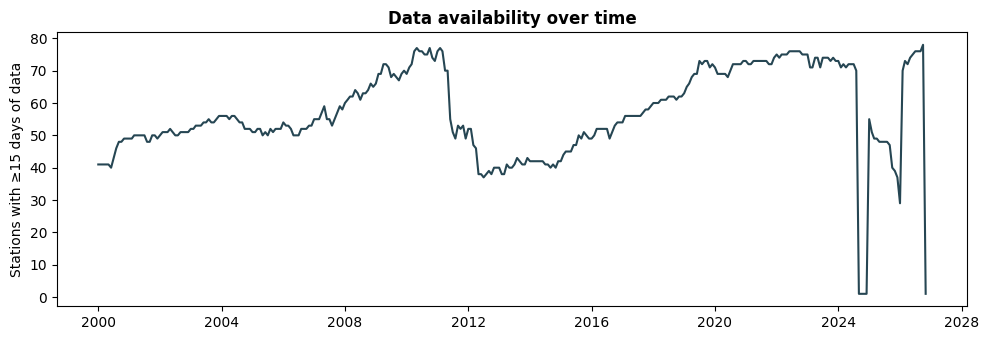

In [15]:
# ── HOW MANY STATIONS REPORT DATA EACH MONTH? ───────────────────────────────────
active = (df_flow.assign(month=df_flow['date'].dt.to_period('M'))
          .groupby(['month', 'station_code']).size().rename('n_days').reset_index())
active = active[active['n_days'] >= 15]
stations_per_month = active.groupby('month')['station_code'].nunique()
print(stations_per_month.loc['2024-01':'2026-10'].to_string())

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(stations_per_month.index.to_timestamp(), stations_per_month.values, color='#264653')
ax.set_ylabel('Stations with ≥15 days of data')
ax.set_title('Data availability over time', fontweight='bold')
plt.tight_layout()
plt.show()

In [16]:
zero_share = df_flow.groupby('station_code')['value'].apply(lambda v: (v == 0).mean() * 100)
stations_trends['zeros_pct'] = stations_trends['station_code'].map(zero_share)

print(stations_trends.loc[stations_trends['zeros_pct'] > 5,['station', 'zeros_pct', 'sen_slope_pct_per_year']].sort_values('zeros_pct', ascending=False).to_string(index=False))

                                             station  zeros_pct  sen_slope_pct_per_year
                 Aforament - Santa Llogaia d'Àlguema  56.780051                0.000000
                  Aforament - Riudellots de la Selva  40.790656               -0.094423
                    Aforament - Santa Cristina d'Aro  36.179333                0.002013
                Aforament - Serra de Daró (riu Daró)  31.641940                0.000000
                               Aforament - Campllong  26.402567                0.026454
                               Aforament - Tarragona  19.833275               -0.080531
                               Aforament - Vilabella  18.860868               -1.488840
               Aforament - Qualitat - Pont de Molins  17.664190               -0.749321
              Aforament - la Bisbal d'Empordà (Daró)  15.175524                0.000000
        Aforament - Fogars de la Selva (Pont Eiffel)  14.103155               -0.874427
Aforament - Qualitat - Fogars de

## 6. Robustness checks

Does the conclusion depend on our choices? We repeat the analysis with different filters (scenarios A-E), with and without the autocorrelation correction, in two time windows, and moving the end year of the series. We also control for multiple testing across stations with the Benjamini-Hochberg false discovery rate.

In [17]:
runs = {
    'A: baseline (current)': {},
    'B: + max gap 36 months': {'max_gap': 36},
    'C: + Hamed-Rao only': {'hamed_rao': True},
    'D: both': {'max_gap': 36, 'hamed_rao': True},
    'E: relaxed (10-year span, 40% coverage)': {'min_span': 10, 'min_cov': 40, 'hamed_rao': True},
}
rows = []
for label, kw in runs.items():
    t = build_trends(df_flow, **kw)
    s = t['sen_slope_pct_per_year']
    sig = t['significant'].astype(bool)
    rows.append({'run': label, 'stations': len(t),
                 'negative': int((s < 0).sum()), 'neg_signif': int(((s < 0) & sig).sum()),
                 'positive': int((s > 0).sum()), 'pos_signif': int(((s > 0) & sig).sum()),
                 'zero': int((s == 0).sum())})
print(pd.DataFrame(rows).to_string(index=False))

c:\Users\cadam\AppData\Local\Programs\Python\Python313\Lib\site-packages\pymannkendall\pymannkendall.py:103: RuntimeWarning: invalid value encountered in sqrt
  z = (s + 1)/np.sqrt(var_s)
c:\Users\cadam\AppData\Local\Programs\Python\Python313\Lib\site-packages\pymannkendall\pymannkendall.py:103: RuntimeWarning: invalid value encountered in sqrt
  z = (s + 1)/np.sqrt(var_s)
c:\Users\cadam\AppData\Local\Programs\Python\Python313\Lib\site-packages\pymannkendall\pymannkendall.py:103: RuntimeWarning: invalid value encountered in sqrt
  z = (s + 1)/np.sqrt(var_s)


                                    run  stations  negative  neg_signif  positive  pos_signif  zero
                  A: baseline (current)        63        44          24        15           4     4
                 B: + max gap 36 months        49        34          18        12           2     3
                    C: + Hamed-Rao only        62        43          18        15           2     4
                                D: both        48        33          15        12           0     3
E: relaxed (10-year span, 40% coverage)        76        52          22        19           4     5


38 stations pass the filters in both periods


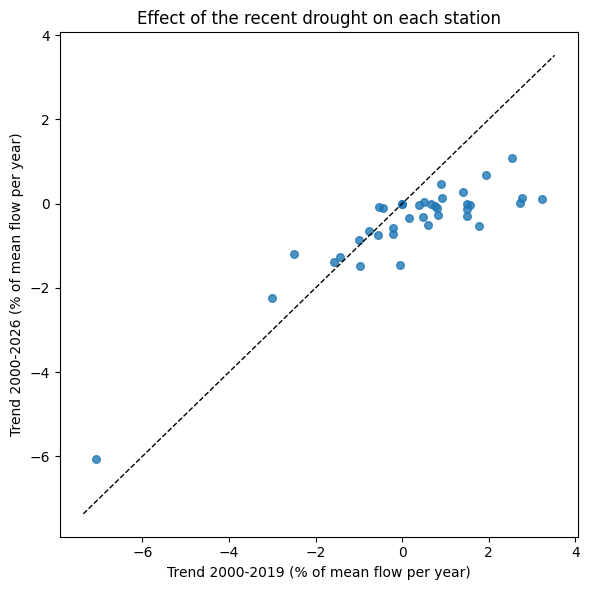

In [18]:
trends_pre2020 = build_trends(df_flow[df_flow['date'] < '2020-01-01'], max_gap=36, hamed_rao=True)

cmp = stations_trends[['station_code', 'station', 'basin', 'sen_slope_pct_per_year']].merge(
    trends_pre2020[['station_code', 'sen_slope_pct_per_year']],
    on='station_code', suffixes=('_full', '_pre2020'))
print(f'{len(cmp)} stations pass the filters in both periods')

vals = cmp[['sen_slope_pct_per_year_pre2020', 'sen_slope_pct_per_year_full']]
lim = [vals.min().min() - 0.3, vals.max().max() + 0.3]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(cmp['sen_slope_pct_per_year_pre2020'], cmp['sen_slope_pct_per_year_full'], s=30, alpha=0.8)
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel("Trend 2000-2019 (% of mean flow per year)")
ax.set_ylabel("Trend 2000-2026 (% of mean flow per year)")
ax.set_title('Effect of the recent drought on each station')
plt.tight_layout()
plt.show()

In [19]:
col_a, col_b = 'sen_slope_pct_per_year_pre2020', 'sen_slope_pct_per_year_full'
print('Spearman between windows:', round(cmp[[col_a, col_b]].corr(method='spearman').iloc[0, 1], 2))
print('Share negative 2000-2019:', round((cmp[col_a] < 0).mean() * 100), '%')
print('Share negative 2000-2026:', round((cmp[col_b] < 0).mean() * 100), '%')

Spearman between windows: 0.78
Share negative 2000-2019: 37 %
Share negative 2000-2026: 66 %


In [20]:
by_basin = (cmp.groupby('basin')[[col_a, col_b]].median()
            .assign(n=cmp.groupby('basin').size())
            .sort_values(col_b))
print(by_basin.round(2).to_string())

                                sen_slope_pct_per_year_pre2020  sen_slope_pct_per_year_full   n
basin                                                                                          
El Gaià                                                  -0.98                        -1.49   1
Riera De Riudecanyes                                     -0.04                        -1.46   1
El Fluvià                                                -1.96                        -1.23   2
El Besòs                                                 -0.04                        -0.76   2
La Muga                                                  -0.22                        -0.64   5
La Tordera                                                0.15                        -0.33   3
El Llobregat                                              0.90                        -0.19  10
El Francolí                                               0.14                        -0.18   2
El Daró                                 

In [21]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)   # Hamed-Rao can return NaN variance for some windows

rows = []
for end_year in range(2017, 2027):
    t = build_trends(df_flow[df_flow['date'] <= f'{end_year}-12-31'], max_gap=36, hamed_rao=True)
    s = t['sen_slope_pct_per_year']
    rows.append({'end_year': end_year, 'stations': len(t),
                 'pct_negative': round((s < 0).mean() * 100),
                 'median_slope': round(s.median(), 2),
                 'signif_neg': int(((s < 0) & t['significant'].astype(bool)).sum())})
end_sens = pd.DataFrame(rows)
print(end_sens.to_string(index=False))

 end_year  stations  pct_negative  median_slope  signif_neg
     2017        38            39          0.14           9
     2018        39            36          0.71           8
     2019        40            38          0.49           8
     2020        40            30          0.71           1
     2021        41            32          0.34           4
     2022        43            40          0.03           7
     2023        48            71         -0.44          17
     2024        48            77         -0.61          18
     2025        50            74         -0.49          19
     2026        48            69         -0.28          15


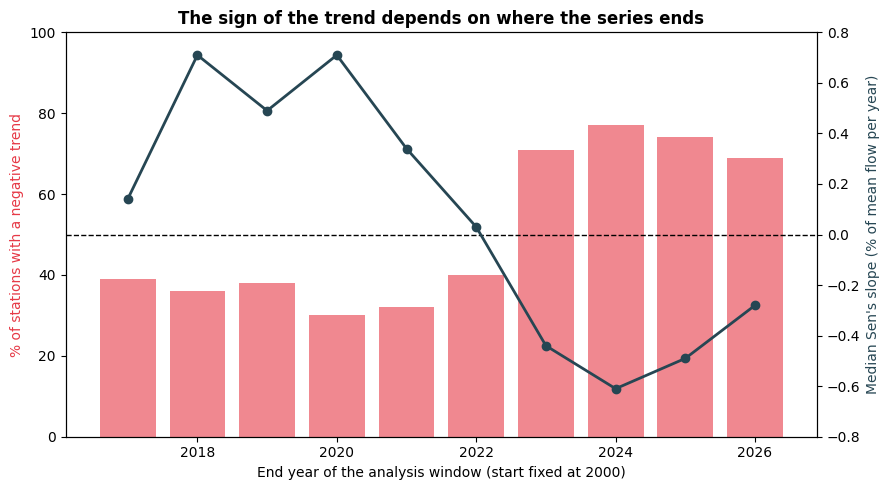

In [22]:
# ── KEY FIGURE: HOW THE RESULT DEPENDS ON THE END YEAR ──────────────────────────
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(end_sens['end_year'], end_sens['pct_negative'], color='#e63946', alpha=0.6)
ax1.axhline(50, color='black', lw=1, ls='--')
ax1.set_xlabel('End year of the analysis window (start fixed at 2000)')
ax1.set_ylabel('% of stations with a negative trend', color='#e63946')
ax1.set_ylim(0, 100)

ax2 = ax1.twinx()
ax2.plot(end_sens['end_year'], end_sens['median_slope'], color='#264653', marker='o', lw=2)
ax2.set_ylim(-0.8, 0.8)
ax2.set_ylabel("Median Sen's slope (% of mean flow per year)", color='#264653')

ax1.set_title('The sign of the trend depends on where the series ends', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '03_end_year_sensitivity.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Drought, storm Gloria and reservoirs

The most important feature of the record is its interannual variability. Flow anomalies by hydrological year (October-September) are shown next to reservoir storage, and the January 2020 storm Gloria is measured at each station against its own history of annual maxima.

67 stations with ≥10 complete hydrological years
hydro_year  2000  2001  2002  2003   2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019   2020  2021  2022  2023  2024  2025  2026
median     -35.0  -6.0  -4.0  10.0   91.0 -49.0  17.0 -48.0 -46.0  12.0  11.0  18.0  -6.0   7.0 -27.0   3.0 -41.0 -20.0  -4.0  24.0  114.0 -38.0 -54.0 -73.0 -70.0   9.0  32.0
q25        -35.0 -54.0 -31.0 -16.0   61.0 -63.0  -6.0 -59.0 -72.0  -6.0 -21.0  -8.0 -22.0  -6.0 -46.0 -14.0 -71.0 -43.0 -44.0   7.0   69.0 -60.0 -71.0 -88.0 -85.0   9.0   8.0
q75        -35.0  35.0  52.0  34.0  167.0 -29.0  40.0 -27.0 -25.0  32.0  32.0  47.0  31.0  32.0 -14.0  30.0 -22.0   1.0  31.0  60.0  173.0 -17.0 -39.0 -62.0 -63.0   9.0  61.0
n            1.0  44.0  44.0  47.0   50.0  44.0  44.0  47.0  53.0  56.0  60.0  48.0  33.0  36.0  41.0  38.0  48.0  53.0  56.0  60.0   58.0  60.0  61.0  62.0  59.0   1.0  28.0


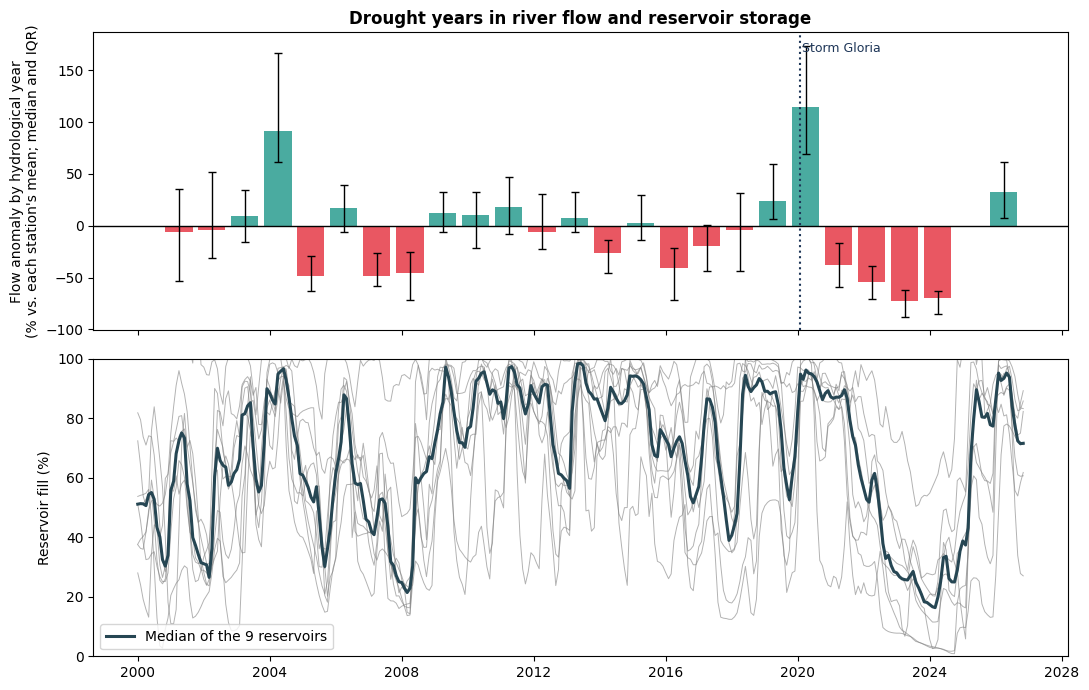

In [23]:
# ── DROUGHT FIGURE: FLOW ANOMALY vs. RESERVOIR FILL ─────────────────────────────
MIN_HY_DAYS, MIN_HY = 300, 10        # a hydrological year needs ≥300 days; a station needs ≥10 such years

d = df_flow.copy()
d['hydro_year'] = d['date'].dt.year + (d['date'].dt.month >= 10).astype(int)   # Oct-Sep
hy = d.groupby(['station_code', 'hydro_year'])['value'].agg(mean_flow='mean', n_days='count').reset_index()
hy = hy[hy['n_days'] >= MIN_HY_DAYS]
hy = hy[hy.groupby('station_code')['hydro_year'].transform('count') >= MIN_HY].copy()
hy['anomaly_pct'] = (hy['mean_flow'] / hy.groupby('station_code')['mean_flow'].transform('mean') - 1) * 100
print(f"{hy['station_code'].nunique()} stations with ≥{MIN_HY} complete hydrological years")

by_year = hy.groupby('hydro_year')['anomaly_pct'].agg(
    median='median', q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n='count')
print(by_year.round(0).T.to_string())

by_year = by_year[by_year['n'] >= 10]       # drop years supported by fewer than 10 stations

res_m = df_res.set_index('date').groupby('reservoir')['pct_full'].resample('MS').mean().reset_index()
res_median = res_m.groupby('date')['pct_full'].median()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
x = pd.to_datetime(by_year.index.astype(str) + '-04-01')       # centre of each Oct-Sep year
colors = ['#e63946' if v < 0 else '#2a9d8f' for v in by_year['median']]
ax1.bar(x, by_year['median'], width=300, color=colors, alpha=0.85)
ax1.errorbar(x, by_year['median'], yerr=[by_year['median'] - by_year['q25'], by_year['q75'] - by_year['median']],
             fmt='none', ecolor='black', lw=1, capsize=3)
ax1.axhline(0, color='black', lw=1)
ax1.axvline(pd.Timestamp('2020-01-21'), color='#1d3557', ls=':', lw=1.5)
ax1.text(pd.Timestamp('2020-02-15'), ax1.get_ylim()[1] * 0.9, 'Storm Gloria', color='#1d3557', fontsize=9)
ax1.set_ylabel('Flow anomaly by hydrological year\n(% vs. each station\'s mean; median and IQR)')
ax1.set_title('Drought years in river flow and reservoir storage', fontweight='bold')

for _, g in res_m.groupby('reservoir'):
    ax2.plot(g['date'], g['pct_full'], color='grey', lw=0.7, alpha=0.6)
ax2.plot(res_median.index, res_median.values, color='#264653', lw=2.2, label='Median of the 9 reservoirs')
ax2.set_ylim(0, 100)
ax2.set_ylabel('Reservoir fill (%)')
ax2.legend(loc='lower left')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '04_drought_flow_reservoirs.png'), dpi=150, bbox_inches='tight')
plt.show()

In [24]:
# ── STORM GLORIA (JAN 2020): HOW EXCEPTIONAL WAS IT AT EACH STATION? ───────────
GLORIA = ('2020-01-19', '2020-01-27')
MIN_DAYS_PER_YEAR, MIN_YEARS = 270, 8

df_y = df_flow.assign(year=df_flow['date'].dt.year)
gl = df_y[(df_y['date'] >= GLORIA[0]) & (df_y['date'] <= GLORIA[1])]
peak = gl.groupby('station_code').agg(gloria_peak=('value', 'max'), gloria_days=('value', 'count'))
peak = peak[peak['gloria_days'] >= 5]                       # station must have recorded most of the event

yearly = (df_y[df_y['year'] != 2020].groupby(['station_code', 'year'])['value']
          .agg(annual_max='max', n_days='count').reset_index())
yearly = yearly[yearly['n_days'] >= MIN_DAYS_PER_YEAR]      # only years with near-complete records

rows = []
for code, p in peak.iterrows():
    y = yearly.loc[yearly['station_code'] == code, 'annual_max']
    if len(y) < MIN_YEARS:
        continue
    rows.append({'station_code': code, 'gloria_peak': p['gloria_peak'], 'n_years': len(y) + 1,
                 'median_annual_max': y.median(), 'rank': int((y > p['gloria_peak']).sum()) + 1})

gloria_tbl = pd.DataFrame(rows)
gloria_tbl['ratio_to_median_max'] = gloria_tbl['gloria_peak'] / gloria_tbl['median_annual_max']
gloria_tbl.loc[gloria_tbl['median_annual_max'] < 0.5, 'ratio_to_median_max'] = np.nan   # ratio is meaningless when the denominator is tiny
gloria_tbl = gloria_tbl.merge(df_flow.groupby('station_code')[['station', 'basin']].first().reset_index(),
                              on='station_code')

print(f"Stations with usable data: {len(gloria_tbl)}")
print(f"  Gloria = highest daily flow on record: {(gloria_tbl['rank'] == 1).sum()}")
print(f"  Gloria among the 3 highest: {(gloria_tbl['rank'] <= 3).sum()}")
print(gloria_tbl.sort_values('ratio_to_median_max', ascending=False)
      [['station', 'basin', 'gloria_peak', 'median_annual_max', 'ratio_to_median_max', 'rank', 'n_years']]
      .head(12).round(2).to_string(index=False))

Stations with usable data: 63
  Gloria = highest daily flow on record: 32
  Gloria among the 3 highest: 46
                                           station        basin  gloria_peak  median_annual_max  ratio_to_median_max  rank  n_years
        Aforament - la Cellera de Ter (Pasteral I)       El Ter       725.58              20.13                36.05     1       19
Aforament - Cornudella de Montsant (Toll del Forn)       L'ebre        33.39               1.50                22.26     1       14
                 Aforament - Vilada (Riera Vilada) El Llobregat        18.33               1.12                16.34     1       11
                                Aforament - Anglès       El Ter       141.72               9.14                15.51     1       15
                           Aforament - Sant Celoni   La Tordera       108.79               7.33                14.84     1       24
                  Aforament - Montornès del Vallès     El Besòs        59.23               4.67      

## 8. Reservoir regulation: regulated vs. natural stations

Stations are classified as *regulated* (main stem downstream of one of the nine reservoirs), *natural* or *managed_other* (canals and weirs dominated by abstractions and wastewater), based on river geography. Two hypotheses were fixed before testing, with a threshold of 0.025 per test: **H1** regulated stations have flatter trends; **H2** they fall less during the 2022-2024 drought. Because regulated stations are on much larger rivers, the comparison is repeated for rivers of similar size and in a regression adjusted for river size.

In [25]:
# ── REGULATION: DRAFT CLASSIFICATION (VERIFY ON A MAP BEFORE USING) ─────────────
reg_status = {
    # Ter main stem, below Sau / Susqueda
    'EA060': 'regulated', 'EA121_C4121_E09': 'regulated', 'EA010': 'regulated', 'EA080': 'regulated',
    # Llobregat main stem, below La Baells
    'EA066_C4066': 'regulated', 'EA067_C4067': 'regulated', 'EA023': 'regulated',
    'EA084_A084': 'regulated', 'EA005_C4005': 'regulated', 'EA049_C4049': 'regulated',
    # Cardener, below Llosa del Cavall / Sant Ponç
    'EA001b_C4001b': 'regulated', 'EA068': 'regulated',
    # Muga, below Darnius-Boadella; Foix, below the Foix reservoir
    'EA125': 'regulated', 'EA052': 'regulated', 'EA008': 'regulated',
    # Tributaries of the Ter (no listed reservoir)
    'EA061': 'natural', 'EA020': 'natural', 'EA124': 'natural', 'EA009': 'natural', 'EA116': 'natural',
    'EA120': 'natural', 'EA101': 'natural', 'EA027': 'natural', 'EA115': 'natural', 'EA123': 'natural',
    # Upper Ter, above Sau
    'EA072_C4072': 'natural', 'EA072a': 'natural', 'EA019': 'natural', 'EA141': 'natural',
    'EA140': 'natural', 'EA085_C4085': 'natural',
    # Anoia and other Llobregat tributaries / headwaters above La Baells
    'EA011': 'natural', 'EA004': 'natural', 'EA074': 'natural', 'EA039_C4039': 'natural',
    'EA065': 'natural', 'EA076': 'natural', 'EA134': 'natural', 'EA110': 'natural',
    'EA086': 'natural', 'EA078_C4078': 'natural', 'EA087': 'natural', 'EA094': 'natural', 'EA095': 'natural',
    # Muga: upstream of the reservoir and tributaries
    'EA051': 'natural', 'EA050': 'natural', 'EA088': 'natural', 'EA082': 'natural',
        # --- checked on a map ---
    'EA012': 'regulated',                                      # Boadella, just below the Darnius-Boadella dam
    'EA063': 'natural', 'EA077': 'natural', 'EA096': 'natural',  # Navès, Sallent, Cercs
    'EA014': 'natural', 'EA033_C4033': 'natural', 'EA085_C4085_EA120': 'natural',
    'EA041': 'natural', 'EA111': 'natural', 'EA112': 'natural',  # Cornudella (Siurana)
    'EA097_C4097': 'natural', 'EA098': 'natural',                # Guixers
    'EA138': 'natural', 'EA139': 'natural',                      # Camprodon
    'EA093_C4007': 'managed_other', 'EA099': 'managed_other',    # canal / weir, see note
}
reg_basins = ['El Ter', 'El Llobregat', 'La Muga', 'El Foix', 'Riera De Riudecanyes', "L'ebre"]

names = df_flow.groupby('station_code')[['station', 'basin']].first().reset_index()
names['regulation'] = names['station_code'].map(reg_status)
# basins with none of the 9 reservoirs are 'natural' by default; anything else not listed needs checking
names.loc[names['regulation'].isna() & ~names['basin'].isin(reg_basins), 'regulation'] = 'natural'
names['regulation'] = names['regulation'].fillna('verify')

print(names['regulation'].value_counts().to_string())
print(names.loc[names['regulation'] == 'verify', ['station_code', 'station', 'basin']].to_string(index=False))

regulation
natural          70
regulated        16
managed_other     2
Empty DataFrame
Columns: [station_code, station, basin]
Index: []


In [26]:
# ── REGULATED vs NATURAL: H1 (flatter trends) AND H2 (smaller drought anomaly) ───
from scipy.stats import mannwhitneyu

reg_map = names.set_index('station_code')['regulation']
stations_trends['regulation'] = stations_trends['station_code'].map(reg_map)

g = stations_trends[stations_trends['regulation'].isin(['regulated', 'natural'])]
a = g.loc[g['regulation'] == 'regulated', 'sen_slope_pct_per_year'].abs()
b = g.loc[g['regulation'] == 'natural', 'sen_slope_pct_per_year'].abs()
u1, p1 = mannwhitneyu(a, b, alternative='two-sided')
print(f'H1 |trend| (% of mean flow/year): regulated n={len(a)} median={a.median():.2f} | '
      f'natural n={len(b)} median={b.median():.2f} | Mann-Whitney p={p1:.3f}')

drought = (hy[hy['hydro_year'].between(2022, 2024)].groupby('station_code')
           .agg(anomaly_2022_24=('anomaly_pct', 'mean'), n_years=('anomaly_pct', 'count')).reset_index())
drought = drought[drought['n_years'] >= 2].merge(names, on='station_code')
drought = drought[drought['regulation'].isin(['regulated', 'natural'])]
a2 = drought.loc[drought['regulation'] == 'regulated', 'anomaly_2022_24']
b2 = drought.loc[drought['regulation'] == 'natural', 'anomaly_2022_24']
u2, p2 = mannwhitneyu(a2, b2, alternative='two-sided')
print(f'H2 drought anomaly 2022-24 (%): regulated n={len(a2)} median={a2.median():.0f} | '
      f'natural n={len(b2)} median={b2.median():.0f} | Mann-Whitney p={p2:.3f}')

H1 |trend| (% of mean flow/year): regulated n=13 median=0.53 | natural n=34 median=0.32 | Mann-Whitney p=0.915
H2 drought anomaly 2022-24 (%): regulated n=14 median=-57 | natural n=46 median=-70 | Mann-Whitney p=0.035


In [27]:
# ── H2 SENSITIVITY: HOW DO THE CHOICES CHANGE THE RESULT? ───────────────────────
def h2_test(reg_series):
    dr = (hy[hy['hydro_year'].between(2022, 2024)].groupby('station_code')
            .agg(anomaly=('anomaly_pct', 'mean'), n_years=('anomaly_pct', 'count')).reset_index())
    dr = dr[dr['n_years'] >= 2]
    dr['regulation'] = dr['station_code'].map(reg_series)
    a = dr.loc[dr['regulation'] == 'regulated', 'anomaly']
    b = dr.loc[dr['regulation'] == 'natural', 'anomaly']
    return len(a), a.median(), len(b), b.median(), mannwhitneyu(a, b, alternative='two-sided').pvalue

base = names.set_index('station_code')['regulation']
lower_llobregat = ['EA084_A084', 'EA005_C4005', 'EA049_C4049']

scenarios = {
    'as classified':                  base,
    'managed_other -> regulated':     base.replace('managed_other', 'regulated'),
    'managed_other -> natural':       base.replace('managed_other', 'natural'),
    'lower Llobregat also excluded':  base.where(~base.index.isin(lower_llobregat), 'managed_other'),
}
for label, ser in scenarios.items():
    n_a, m_a, n_b, m_b, p = h2_test(ser)
    print(f'{label:32s} regulated n={n_a} median={m_a:.0f}% | natural n={n_b} median={m_b:.0f}% | p={p:.3f}')

as classified                    regulated n=14 median=-57% | natural n=46 median=-70% | p=0.035
managed_other -> regulated       regulated n=16 median=-57% | natural n=46 median=-70% | p=0.024
managed_other -> natural         regulated n=14 median=-57% | natural n=48 median=-70% | p=0.042
lower Llobregat also excluded    regulated n=13 median=-58% | natural n=46 median=-70% | p=0.045


In [28]:
# ── H2 CONFOUNDING CHECK: RIVER SIZE ────────────────────────────────────────────
print(names[names['regulation'] == 'regulated'].groupby('basin').size()
      .rename('regulated stations per basin').to_string())

from scipy.stats import spearmanr

size = hy.groupby('station_code')['mean_flow'].mean().rename('mean_flow')
dr = (hy[hy['hydro_year'].between(2022, 2024)].groupby('station_code')
        .agg(anomaly=('anomaly_pct', 'mean'), n_years=('anomaly_pct', 'count')).reset_index())
dr = dr[dr['n_years'] >= 2].merge(names[['station_code', 'regulation']], on='station_code').merge(size, on='station_code')
dr = dr[dr['regulation'].isin(['regulated', 'natural'])]

print()
print(dr.groupby('regulation')['mean_flow'].describe()[['count', '25%', '50%', '75%']].round(2).to_string())
rho, p_rho = spearmanr(dr['mean_flow'], dr['anomaly'])
print(f'\nSpearman (river size vs. drought anomaly): rho={rho:.2f}, p={p_rho:.3f}')

print()
for thr in [0.5, 1, 2]:
    sub = dr[dr['mean_flow'] >= thr]
    a = sub.loc[sub['regulation'] == 'regulated', 'anomaly']
    b = sub.loc[sub['regulation'] == 'natural', 'anomaly']
    if len(a) >= 3 and len(b) >= 3:
        p = mannwhitneyu(a, b, alternative='two-sided').pvalue
        print(f'mean flow >= {thr} m3/s: regulated n={len(a)} median={a.median():.0f}% | '
              f'natural n={len(b)} median={b.median():.0f}% | p={p:.3f}')
    else:
        print(f'mean flow >= {thr} m3/s: too few stations (regulated n={len(a)}, natural n={len(b)})')

basin
El Foix         1
El Llobregat    8
El Ter          4
La Muga         3

            count   25%   50%    75%
regulation                          
natural      46.0  0.27  0.63   1.12
regulated    14.0  2.38  6.17  10.36

Spearman (river size vs. drought anomaly): rho=0.48, p=0.000

mean flow >= 0.5 m3/s: regulated n=13 median=-58% | natural n=27 median=-64% | p=0.436
mean flow >= 1 m3/s: regulated n=13 median=-58% | natural n=14 median=-55% | p=0.903
mean flow >= 2 m3/s: regulated n=11 median=-56% | natural n=8 median=-51% | p=0.310


In [29]:
# ── H2 ADJUSTED FOR RIVER SIZE: NESTED MODELS + LEAVE-ONE-BASIN-OUT ──────────────
import statsmodels.formula.api as smf

mdl = dr.merge(names[['station_code', 'basin']], on='station_code').copy()
mdl['log_size'] = np.log10(mdl['mean_flow'])
mdl['regulated'] = (mdl['regulation'] == 'regulated').astype(int)

models = {'M0: intercept only':     'anomaly ~ 1',
          'M1: river size':         'anomaly ~ log_size',
          'M2: size + regulation':  'anomaly ~ log_size + regulated'}
rows = []
for label, formula in models.items():
    fit = smf.ols(formula, data=mdl).fit()
    rows.append({'model': label, 'AIC': round(fit.aic, 1), 'R2': round(fit.rsquared, 2)})
print(pd.DataFrame(rows).to_string(index=False))

fit2 = smf.ols('anomaly ~ log_size + regulated', data=mdl).fit(cov_type='HC3')
ci = fit2.conf_int().loc['regulated']
print(f"\nRegulation effect adjusted for river size: {fit2.params['regulated']:+.1f} percentage points "
      f"(95% CI {ci[0]:+.1f} to {ci[1]:+.1f}, p={fit2.pvalues['regulated']:.3f})")

loo = []
for b in mdl['basin'].unique():
    sub = mdl[mdl['basin'] != b]
    if sub['regulated'].nunique() < 2:
        continue
    f = smf.ols('anomaly ~ log_size + regulated', data=sub).fit()
    loo.append({'basin left out': b, 'regulation effect (pp)': round(f.params['regulated'], 1), 'n': len(sub)})
print('\nLeave-one-basin-out:')
print(pd.DataFrame(loo).to_string(index=False))

                model   AIC    R2
   M0: intercept only 523.4 -0.00
       M1: river size 518.5  0.11
M2: size + regulation 520.5  0.11

Regulation effect adjusted for river size: -0.1 percentage points (95% CI -10.3 to +10.2, p=0.989)

Leave-one-basin-out:
                basin left out  regulation effect (pp)  n
                  El Llobregat                    -0.2 43
                       El Gaià                    -0.1 59
                       El Foix                    -2.8 59
                        El Ter                     1.6 45
                       La Muga                     1.8 53
                     El Fluvià                     0.3 58
          Riera De Riudecanyes                    -0.1 59
                    La Tordera                    -0.8 56
                   El Francolí                    -0.1 58
                      El Besòs                    -0.2 56
                        L'ebre                     0.8 57
Rieres Del Cap De Begur-blanes                

## 9. Exploratory hypotheses: WWTP influence

Does wastewater effluent offset the decline in flow? Three measures are tested: the population served by WWTPs within 20 km, the ratio between the design flow of WWTPs discharging into the same river and the river's mean flow, and three station categories. A first measure based on summing WWTPs within a radius produced physically impossible ratios and is not included. The design flow is a capacity and not the real discharge, and matching by river name cannot tell upstream from downstream.

In [30]:
# ── WWTP LOAD NEAR EACH STATION (DISTANCE-BASED) ────────────────────────────────
RADIUS_KM = 20

def wwtp_load_nearby(x, y, radius_km=RADIUS_KM):
    dist_km = np.sqrt((df_edar['x'] - x)**2 + (df_edar['y'] - y)**2) / 1000
    nearby = df_edar[dist_km <= radius_km]
    return pd.Series({
        'wwtp_load_20km': nearby['population_equivalent'].sum(),
        'n_wwtp_20km': len(nearby)
    })

wwtp_loads = stations_trends.apply(
    lambda row: wwtp_load_nearby(row['x'], row['y']), axis=1
)


stations_trends['wwtp_load_20km'] = wwtp_loads['wwtp_load_20km']
stations_trends['n_wwtp_20km'] = wwtp_loads['n_wwtp_20km']

print(stations_trends[['station', 'basin', 'sen_slope_per_year', 'wwtp_load_20km', 'n_wwtp_20km']].sort_values('wwtp_load_20km', ascending=False).head(10).to_string(index=False))


                                                     station        basin  sen_slope_per_year  wwtp_load_20km  n_wwtp_20km
                        Aforament - Santa Coloma de Gramenet     El Besòs           -0.053797       8018469.0         22.0
Aforament - Sant Vicenç dels Horts (riu - canal de la Dreta) El Llobregat           -0.057639       7988749.0         40.0
                                 Aforament - Sant Joan Despí El Llobregat           -0.013132       7227474.0         18.0
                          Aforament - Castellbell i el Vilar El Llobregat            0.014647       1072258.0         45.0
                                     Aforament - Sant Celoni   La Tordera            0.001178       1060352.0         31.0
                                       Aforament - Tarragona  El Francolí           -0.000637       1012557.0         32.0
                            Aforament - Sant Sadurní d'Anoia El Llobregat           -0.000365        973976.0         59.0
        Aforamen

In [31]:
# ── WHICH STATIONS ARE GOING UP? ────────────────────────────────────────────────
rising = stations_trends[stations_trends['sen_slope_pct_per_year'] > 0].sort_values('sen_slope_pct_per_year', ascending=False)

print(rising[['station', 'basin', 'sen_slope_pct_per_year', 'p_value','mean_flow', 'wwtp_load_20km']].to_string(index=False))

                                           station                          basin  sen_slope_pct_per_year  p_value  mean_flow  wwtp_load_20km
        Aforament - la Cellera de Ter (Pasteral I)                         El Ter                1.079343 0.232424   8.533801        292778.0
          Aforament - Cornudella de Montsant_EA041                         L'ebre                0.772975 0.086987   0.068381         58805.0
                          Aforament - Girona (Ter)                         El Ter                0.672111 0.182546   8.309436        408932.0
                 Aforament - Guardiola de Berguedà                   El Llobregat                0.476950 0.103168   3.404509         85273.0
                           Aforament - Sant Celoni                     La Tordera                0.286183 0.524205   0.411602       1060352.0
Aforament - Sant Joan de les Abadesses (històrica)                         El Ter                0.184533 0.894108   4.242045        133804.0
      

In [32]:
# ── CORRELATION: WWTP LOAD vs. FLOW TREND ───────────────────────────────────────
from scipy.stats import spearmanr

corr, p_corr = spearmanr(stations_trends['wwtp_load_20km'], stations_trends['sen_slope_pct_per_year'])

print(f'Spearman correlation (WWTP load vs. flow trend): {corr:.3f}')
print(f'p-value: {p_corr:.4f}')
print(f'→ {"Statistically significant" if p_corr < 0.05 else "Not statistically significant"} relationship')


Spearman correlation (WWTP load vs. flow trend): 0.067
p-value: 0.6499
→ Not statistically significant relationship


In [33]:
# ── CLASSIFY STATIONS INTO 3 CATEGORIES ─────────────────────────────────────────
WWTP_THRESHOLD_HIGH = 1000000   # hab.eq — clearly urban/WWTP-dominated
Y_MOUNTAIN_THRESHOLD = 4670000  # UTM northing — rough proxy for Pyrenean headwaters

def classify(row):
    if row['wwtp_load_20km'] >= WWTP_THRESHOLD_HIGH:
        return 'WWTP-influenced'
    elif row['y'] >= Y_MOUNTAIN_THRESHOLD:
        return 'Mountain/forest'
    else:
        return 'Aquifer-dependent / lowland'

stations_trends['category'] = stations_trends.apply(classify, axis=1)

print(stations_trends['category'].value_counts())
print()
print(stations_trends.groupby('category')['sen_slope_pct_per_year'].describe())

# ── KRUSKAL-WALLIS TEST: ARE THE 3 GROUPS STATISTICALLY DIFFERENT? ──────────────
from scipy.stats import kruskal

groups = [
    stations_trends[stations_trends['category'] == cat]['sen_slope_pct_per_year'].values
    for cat in stations_trends['category'].unique()
]

h_stat, p_value = kruskal(*groups)

print('KRUSKAL-WALLIS TEST')
print(f'  H-statistic: {h_stat:.3f}')
print(f'  p-value: {p_value:.4f}')
print(f'  → {"Statistically significant difference" if p_value < 0.05 else "No statistically significant difference"} between categories')

category
Aquifer-dependent / lowland    31
Mountain/forest                11
WWTP-influenced                 6
Name: count, dtype: int64

                             count      mean       std       min       25%  \
category                                                                     
Aquifer-dependent / lowland   31.0 -0.690423  1.308554 -6.054961 -1.314492   
Mountain/forest               11.0 -0.442964  0.585135 -1.349496 -0.732593   
WWTP-influenced                6.0 -0.276523  0.606703 -1.383646 -0.413135   

                                  50%       75%       max  
category                                                   
Aquifer-dependent / lowland -0.284251  0.000000  1.079343  
Mountain/forest             -0.569349  0.019089  0.476950  
WWTP-influenced             -0.089597  0.081474  0.286183  
KRUSKAL-WALLIS TEST
  H-statistic: 0.737
  p-value: 0.6916
  → No statistically significant difference between categories


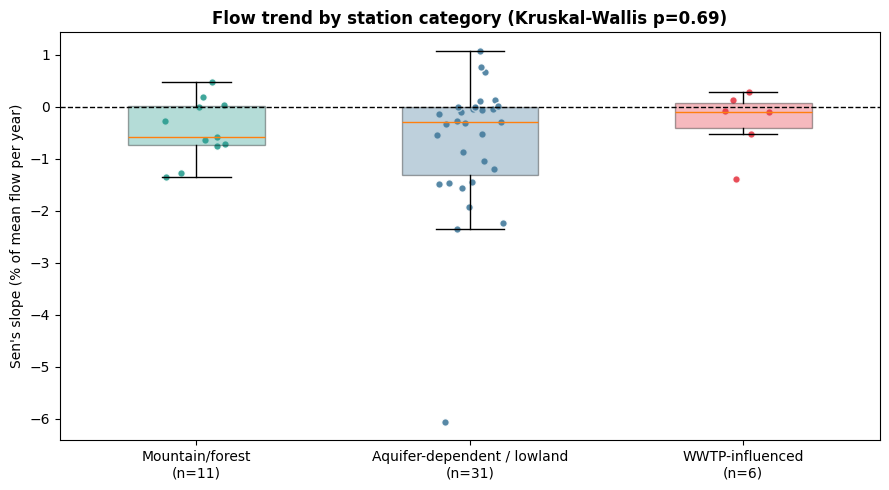

In [34]:
# ── TREND BY CATEGORY (BOXPLOT + INDIVIDUAL STATIONS) ──────────────────────────
order = ['Mountain/forest', 'Aquifer-dependent / lowland', 'WWTP-influenced']
colors = {'Mountain/forest': '#2a9d8f', 'Aquifer-dependent / lowland': '#457b9d', 'WWTP-influenced': '#e63946'}

data = [stations_trends.loc[stations_trends['category'] == c, 'sen_slope_pct_per_year'] for c in order]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.5)
for patch, c in zip(bp['boxes'], order):
    patch.set_facecolor(colors[c])
    patch.set_alpha(0.35)

rng = np.random.default_rng(0)   # fixed seed so the jitter is reproducible
for i, (c, d) in enumerate(zip(order, data), start=1):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d,
               color=colors[c], s=30, alpha=0.9, edgecolor='white')

ax.set_xticks([1, 2, 3])
ax.set_xticklabels([f'{c}\n(n={len(d)})' for c, d in zip(order, data)])
ax.axhline(0, color='black', lw=1, ls='--')
ax.set_ylabel("Sen's slope (% of mean flow per year)")
ax.set_title(f'Flow trend by station category (Kruskal-Wallis p={p_value:.2f})', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, '02_trend_by_category.png'), dpi=150, bbox_inches='tight')
plt.show()

In [35]:
# ── WWTPs DISCHARGING TO THE SAME RIVER AS EACH STATION ─────────────────────────
import re, unicodedata

STOPWORDS = {'el', 'la', 'les', 'l', 'de', 'del', 'd', 'riu', 'riera', 'rec',
             'torrent', 'barranc', 'cabal', 'total'}

def river_key(text):
    if pd.isna(text):
        return None
    t = unicodedata.normalize('NFKD', str(text)).encode('ascii', 'ignore').decode().lower()
    t = re.sub(r'\(.*?\)', ' ', t)                              # drop "(riu + CH)" etc.
    tokens = [w for w in re.split(r'[^a-z]+', t) if w and w not in STOPWORDS]
    return ' '.join(tokens) if tokens else None

desc_col = [c for c in df_flow.columns if c.startswith('descripci')][0]   # avoids accent problems
desc = df_flow.groupby('station_code')[desc_col].first()

stations_trends['river_key'] = stations_trends['station_code'].map(
    lambda c: river_key(re.split(r'cabal', str(desc[c]), flags=re.I)[-1]))
stations_trends['basin_key'] = stations_trends['basin'].map(river_key)

df_edar['river_tokens'] = df_edar['receiving_water'].map(lambda t: set((river_key(t) or '').split()))
df_edar['basin_key'] = df_edar['basin'].map(river_key)

SEA_OR_OTHER = 'mar Mediterrani|Badia|Infiltració|embassament'
not_river = df_edar['receiving_water'].str.contains(SEA_OR_OTHER, case=False, na=False)

MAX_DIST_KM = 25

def same_river_discharge(row):
    cand = df_edar[~not_river & (df_edar['basin_key'] == row['basin_key']) &
                (df_edar['river_tokens'].map(lambda s: set(row['river_key'].split()) <= s))]
    dist_km = np.sqrt((cand['x'] - row['x'])**2 + (cand['y'] - row['y'])**2) / 1000
    cand = cand[dist_km <= MAX_DIST_KM]
    return pd.Series({'n_wwtp_river': len(cand),
                      'wwtp_flow_river_m3s': cand['design_flow_m3_day'].sum() / 86400})

stations_trends[['n_wwtp_river', 'wwtp_flow_river_m3s']] = stations_trends.apply(same_river_discharge, axis=1)
stations_trends['effluent_ratio_river'] = stations_trends['wwtp_flow_river_m3s'] / stations_trends['mean_flow']

cols = ['station', 'river_key', 'n_wwtp_river', 'wwtp_flow_river_m3s', 'effluent_ratio_river',
        'mean_flow', 'sen_slope_pct_per_year', 'p_value']
print(stations_trends.loc[stations_trends['n_wwtp_river'] > 0, cols]
      .sort_values('effluent_ratio_river', ascending=False).head(15).to_string(index=False))

corr_r, p_r = spearmanr(stations_trends['effluent_ratio_river'], stations_trends['sen_slope_pct_per_year'])
print(f'\nSpearman (same-river effluent ratio vs. trend): {corr_r:.3f}, p-value: {p_r:.4f}')

                                                     station river_key  n_wwtp_river  wwtp_flow_river_m3s  effluent_ratio_river  mean_flow  sen_slope_pct_per_year  p_value
                                      Aforament - La Garriga   congost           5.0             0.504086              1.725465   0.292145               -0.133125 0.814616
                        Aforament - Santa Coloma de Gramenet     besos           3.0             1.800926              0.463197   3.888036               -1.383646 0.000221
                            Aforament - Sant Sadurní d'Anoia     anoia           3.0             0.330926              0.317649   1.041797               -0.035004 0.961270
                                     Aforament - Sant Celoni   tordera           3.0             0.107257              0.260584   0.411602                0.286183 0.524205
                                       Aforament - Montblanc  francoli           3.0             0.062593              0.224966   0.278232  

## 10. Interactive map and summary

Stations are colored by trend, with a black outline when the trend is statistically significant, and two switchable layers (2000-2019 and 2000-2026). The summary table and the station-level CSV are saved in the `output` folder.

In [36]:
# ── INTERACTIVE MAP: TWO WINDOWS, SWITCHABLE ────────────────────────────────────
import folium

to_latlon = pyproj.Transformer.from_crs('EPSG:25831', 'EPSG:4326', always_xy=True)

def trend_color(s):
    if s < -1:    return '#d62728'    # strong decline
    if s < -0.25: return '#ff7f0e'    # moderate decline
    if s <= 0.25: return '#bcbd22'    # stable
    if s <= 1:    return '#2ca02c'    # moderate rise
    return '#1f77b4'                  # strong rise

def add_layer(m, table, name, show):
    group = folium.FeatureGroup(name=name, show=show)
    for _, r in table.iterrows():
        lon, lat = to_latlon.transform(r['x'], r['y'])
        sig = bool(r['significant'])
        popup = (f"<b>{r['station']}</b><br>Basin: {r['basin']}<br>"
                 f"Trend: {r['sen_slope_pct_per_year']:+.2f} % of mean flow / year<br>"
                 f"p-value: {r['p_value']:.3f} ({'significant' if sig else 'not significant'})<br>"
                 f"Mean flow: {r['mean_flow']:.2f} m³/s")
        folium.CircleMarker(location=[lat, lon], radius=8,
                            color='black' if sig else 'white', weight=3 if sig else 1,
                            fill=True, fill_color=trend_color(r['sen_slope_pct_per_year']),
                            fill_opacity=0.9, popup=folium.Popup(popup, max_width=260)).add_to(group)
    group.add_to(m)

flow_map = folium.Map(location=[41.8, 1.9], zoom_start=8, tiles='OpenStreetMap')
add_layer(flow_map, stations_trends, f'2000-2026 ({len(stations_trends)} stations)', show=True)
add_layer(flow_map, trends_pre2020, f'2000-2019 ({len(trends_pre2020)} stations)', show=False)
folium.LayerControl(collapsed=False).add_to(flow_map)

legend = '''
<div style="position: fixed; bottom: 30px; right: 30px; width: 250px; background: white; border: 2px solid grey;
     z-index: 9999; font-size: 12px; padding: 10px; border-radius: 5px;">
<b>Flow trend (% of mean flow / year)</b><br>
<i style="background:#d62728;width:12px;height:12px;float:left;margin:3px 8px 0 0;border-radius:50%"></i> &lt; -1<br>
<i style="background:#ff7f0e;width:12px;height:12px;float:left;margin:3px 8px 0 0;border-radius:50%"></i> -1 to -0.25<br>
<i style="background:#bcbd22;width:12px;height:12px;float:left;margin:3px 8px 0 0;border-radius:50%"></i> -0.25 to +0.25<br>
<i style="background:#2ca02c;width:12px;height:12px;float:left;margin:3px 8px 0 0;border-radius:50%"></i> +0.25 to +1<br>
<i style="background:#1f77b4;width:12px;height:12px;float:left;margin:3px 8px 0 0;border-radius:50%"></i> &gt; +1<br>
<small>Black outline = statistically significant (p&lt;0.05)</small>
</div>'''
flow_map.get_root().html.add_child(folium.Element(legend))

flow_map.save(os.path.join(output_dir, 'catalonia_flow_trends_map.html'))
print('✓ Interactive map saved: output/catalonia_flow_trends_map.html')

✓ Interactive map saved: output/catalonia_flow_trends_map.html


In [37]:
# ── FINAL SUMMARY TABLE AND CSV EXPORT ──────────────────────────────────────────
s = stations_trends['sen_slope_pct_per_year']
sig = stations_trends['significant'].astype(bool)

summary = pd.DataFrame({
    'Metric': ['Stations with flow data', 'Stations passing quality filters',
               'Negative trend', 'Negative and significant (p<0.05)',
               'Positive and significant (p<0.05)', "Median Sen's slope (% of mean flow/year)",
               'Spearman between windows (2000-2019 vs 2000-2026)'],
    'Value': [df_flow['station_code'].nunique(), len(stations_trends),
              f'{(s < 0).sum()} ({(s < 0).mean() * 100:.0f}%)',
              int(((s < 0) & sig).sum()), int(((s > 0) & sig).sum()),
              f'{s.median():+.2f}',
              round(cmp[[col_a, col_b]].corr(method='spearman').iloc[0, 1], 2)]
})
print(summary.to_string(index=False))

cols = ['station_code', 'station', 'basin', 'mean_flow', 'sen_slope_pct_per_year', 'p_value',
        'significant', 'span_years', 'coverage_pct', 'longest_gap_months']
stations_trends[cols].to_csv(os.path.join(output_dir, 'station_trends_summary.csv'), index=False)
print('✓ Saved: output/station_trends_summary.csv')

                                           Metric    Value
                          Stations with flow data       88
                 Stations passing quality filters       48
                                   Negative trend 33 (69%)
                Negative and significant (p<0.05)       15
                Positive and significant (p<0.05)        0
         Median Sen's slope (% of mean flow/year)    -0.28
Spearman between windows (2000-2019 vs 2000-2026)     0.78
✓ Saved: output/station_trends_summary.csv


## 11. Conclusions and limitations

- **Most stations decline, and this is robust to the filters** (69-70% in all five scenarios). In the main analysis no station shows a significant increase.
- **The sign of the aggregate trend depends on where the series ends.** Up to 2022 a minority of stations decline; from 2023, with the drought years included, a large majority do. The ranking of stations is stable between windows.
- **Drought and wet years dominate a 26-year record.** 2020 was the wettest hydrological year and 2021-2024 the driest, which the reservoirs confirm.
- **Storm Gloria** was the highest daily flow on record at about half of the stations with usable data.
- **No relationship with wastewater effluent** was found with any of the three measures.
- **No effect of reservoir regulation** was detected once river size is taken into account: the apparent difference in the drought response was explained by regulated stations being on larger rivers.

**Limitations.** The record is short relative to climate variability; only about half of the stations pass the quality filters and several basins have one or two stations; the river network reported a major data gap between September 2024 and early 2026; stations on the same river are not independent; and the WWTP and regulation analyses rely on proxies (design flow, manual classification). These conclusions describe this sequence of years and should not be read as a steady long-term decline.